In [ ]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Load the Zomato classification dataset

df = pd.read_csv('/content/zomato_classification.csv')

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

df.head()

Dataset loaded successfully!
Shape of dataset: (7037, 8)


,restaurant type,num of ratings,avg cost (two people),online_order,table booking,cuisines type,area,Rating_Category
0,Quick Bites,7,200.0,No,No,Fast Food,Bellandur,Average
1,Quick Bites,48,400.0,Yes,No,"Fast Food, Beverages","Byresandra,Tavarekere,Madiwala",Average
2,Cafe,37,400.0,Yes,No,"Cafe, Beverages",Bannerghatta Road,Average
3,Casual Dining,135,550.0,Yes,No,"Biryani, Mughlai, Chinese",Marathahalli,Low
4,Casual Dining,40,700.0,Yes,No,"BBQ, Continental, North Indian, Chinese, Bever...",Bellandur,Low


In [ ]:
# Display column names and dataset information

print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Column Names:
['restaurant type', 'num of ratings', 'avg cost (two people)', 'online_order', 'table booking', 'cuisines type', 'area', 'Rating_Category']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7037 entries, 0 to 7036
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   restaurant type        7037 non-null   object 
 1   num of ratings         7037 non-null   int64  
 2   avg cost (two people)  7037 non-null   float64
 3   online_order           7037 non-null   object 
 4   table booking          7037 non-null   object 
 5   cuisines type          7037 non-null   object 
 6   area                   7037 non-null   object 
 7   Rating_Category        7037 non-null   object 
dtypes: float64(1), int64(1), object(6)
memory usage: 439.9+ KB


In [ ]:
# Display column names and dataset information

print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Column Names:
['restaurant type', 'num of ratings', 'avg cost (two people)', 'online_order', 'table booking', 'cuisines type', 'area', 'Rating_Category']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7037 entries, 0 to 7036
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   restaurant type        7037 non-null   object 
 1   num of ratings         7037 non-null   int64  
 2   avg cost (two people)  7037 non-null   float64
 3   online_order           7037 non-null   object 
 4   table booking          7037 non-null   object 
 5   cuisines type          7037 non-null   object 
 6   area                   7037 non-null   object 
 7   Rating_Category        7037 non-null   object 
dtypes: float64(1), int64(1), object(6)
memory usage: 439.9+ KB


In [ ]:
# Check duplicate rows

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 31


In [ ]:
# Display target class distribution

print("Target Class Distribution:")
print(df['Rating_Category'].value_counts())

Target Class Distribution:
Rating_Category
Average    4711
High       1250
Low        1076
Name: count, dtype: int64


In [ ]:
# Create a copy of the dataset

data = df.copy()

# Remove automatically generated index columns if present
columns_to_drop = [
    'Unnamed: 0',
    'Unnamed: 0.1',
    'restaurant name',
    'rate'
]

# Drop only the columns that actually exist
data = data.drop(
    columns=[col for col in columns_to_drop if col in data.columns],
    errors='ignore'
)

print("Columns after preprocessing:")
print(data.columns.tolist())

Columns after preprocessing:
['restaurant type', 'num of ratings', 'avg cost (two people)', 'online_order', 'table booking', 'cuisines type', 'area', 'Rating_Category']


In [ ]:
# Separate features (X) and target variable (y)

X = data.drop('Rating_Category', axis=1)
y = data['Rating_Category']

print("Features (X):")
print(X.columns.tolist())

print("\nTarget (y):")
print(y.name)

print("\nTarget classes:")
print(y.unique())

Features (X):
['restaurant type', 'num of ratings', 'avg cost (two people)', 'online_order', 'table booking', 'cuisines type', 'area']

Target (y):
Rating_Category

Target classes:
['Average' 'Low' 'High']


In [ ]:
# Identify numerical and categorical columns

numerical_features = X.select_dtypes(include=['int64', 'float64', 'int32', 'float32']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['num of ratings', 'avg cost (two people)']

Categorical Features:
['restaurant type', 'online_order', 'table booking', 'cuisines type', 'area']


In [ ]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (5629, 7)
Testing data shape: (1408, 7)

Training target distribution:
Rating_Category
Average    3768
High       1000
Low         861
Name: count, dtype: int64

Testing target distribution:
Rating_Category
Average    943
High       250
Low        215
Name: count, dtype: int64


In [ ]:
# Preprocessing for numerical features

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Preprocessing for categorical features

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine both preprocessing methods

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
# Create Decision Tree classification model

decision_tree_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        criterion='gini',
        max_depth=5,
        random_state=42
    ))
])

print("Decision Tree model created successfully!")

Decision Tree model created successfully!


In [ ]:
# Train the Decision Tree model

decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [ ]:
# Predict the classes for test data

y_pred = decision_tree_model.predict(X_test)

print("Predictions generated successfully!")
print("First 20 predictions:")
print(y_pred[:20])

Predictions generated successfully!
First 20 predictions:
['Average' 'Average' 'Average' 'High' 'Average' 'Average' 'Average' 'Low'
 'Average' 'Average' 'Average' 'Average' 'Average' 'Average' 'High' 'High'
 'Average' 'Average' 'High' 'Average']


In [ ]:
# Calculate accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Decision Tree Accuracy:", round(accuracy * 100, 2), "%")

Decision Tree Accuracy: 82.6 %


In [ ]:
# Generate classification report

print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

     Average       0.83      0.94      0.88       943
        High       0.73      0.58      0.65       250
         Low       0.94      0.61      0.74       215

    accuracy                           0.83      1408
   macro avg       0.83      0.71      0.76      1408
weighted avg       0.83      0.83      0.82      1408



Confusion Matrix:
[[888  48   7]
 [104 144   2]
 [ 80   4 131]]


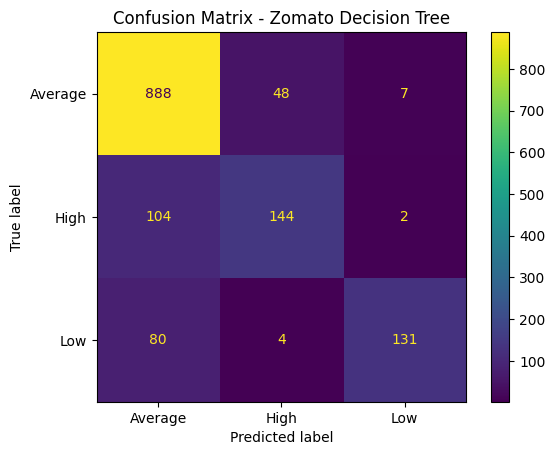

In [ ]:
# Generate confusion matrix

cm = confusion_matrix(y_test, y_pred, labels=decision_tree_model.classes_)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=decision_tree_model.classes_
)

disp.plot()
plt.title("Confusion Matrix - Zomato Decision Tree")
plt.show()

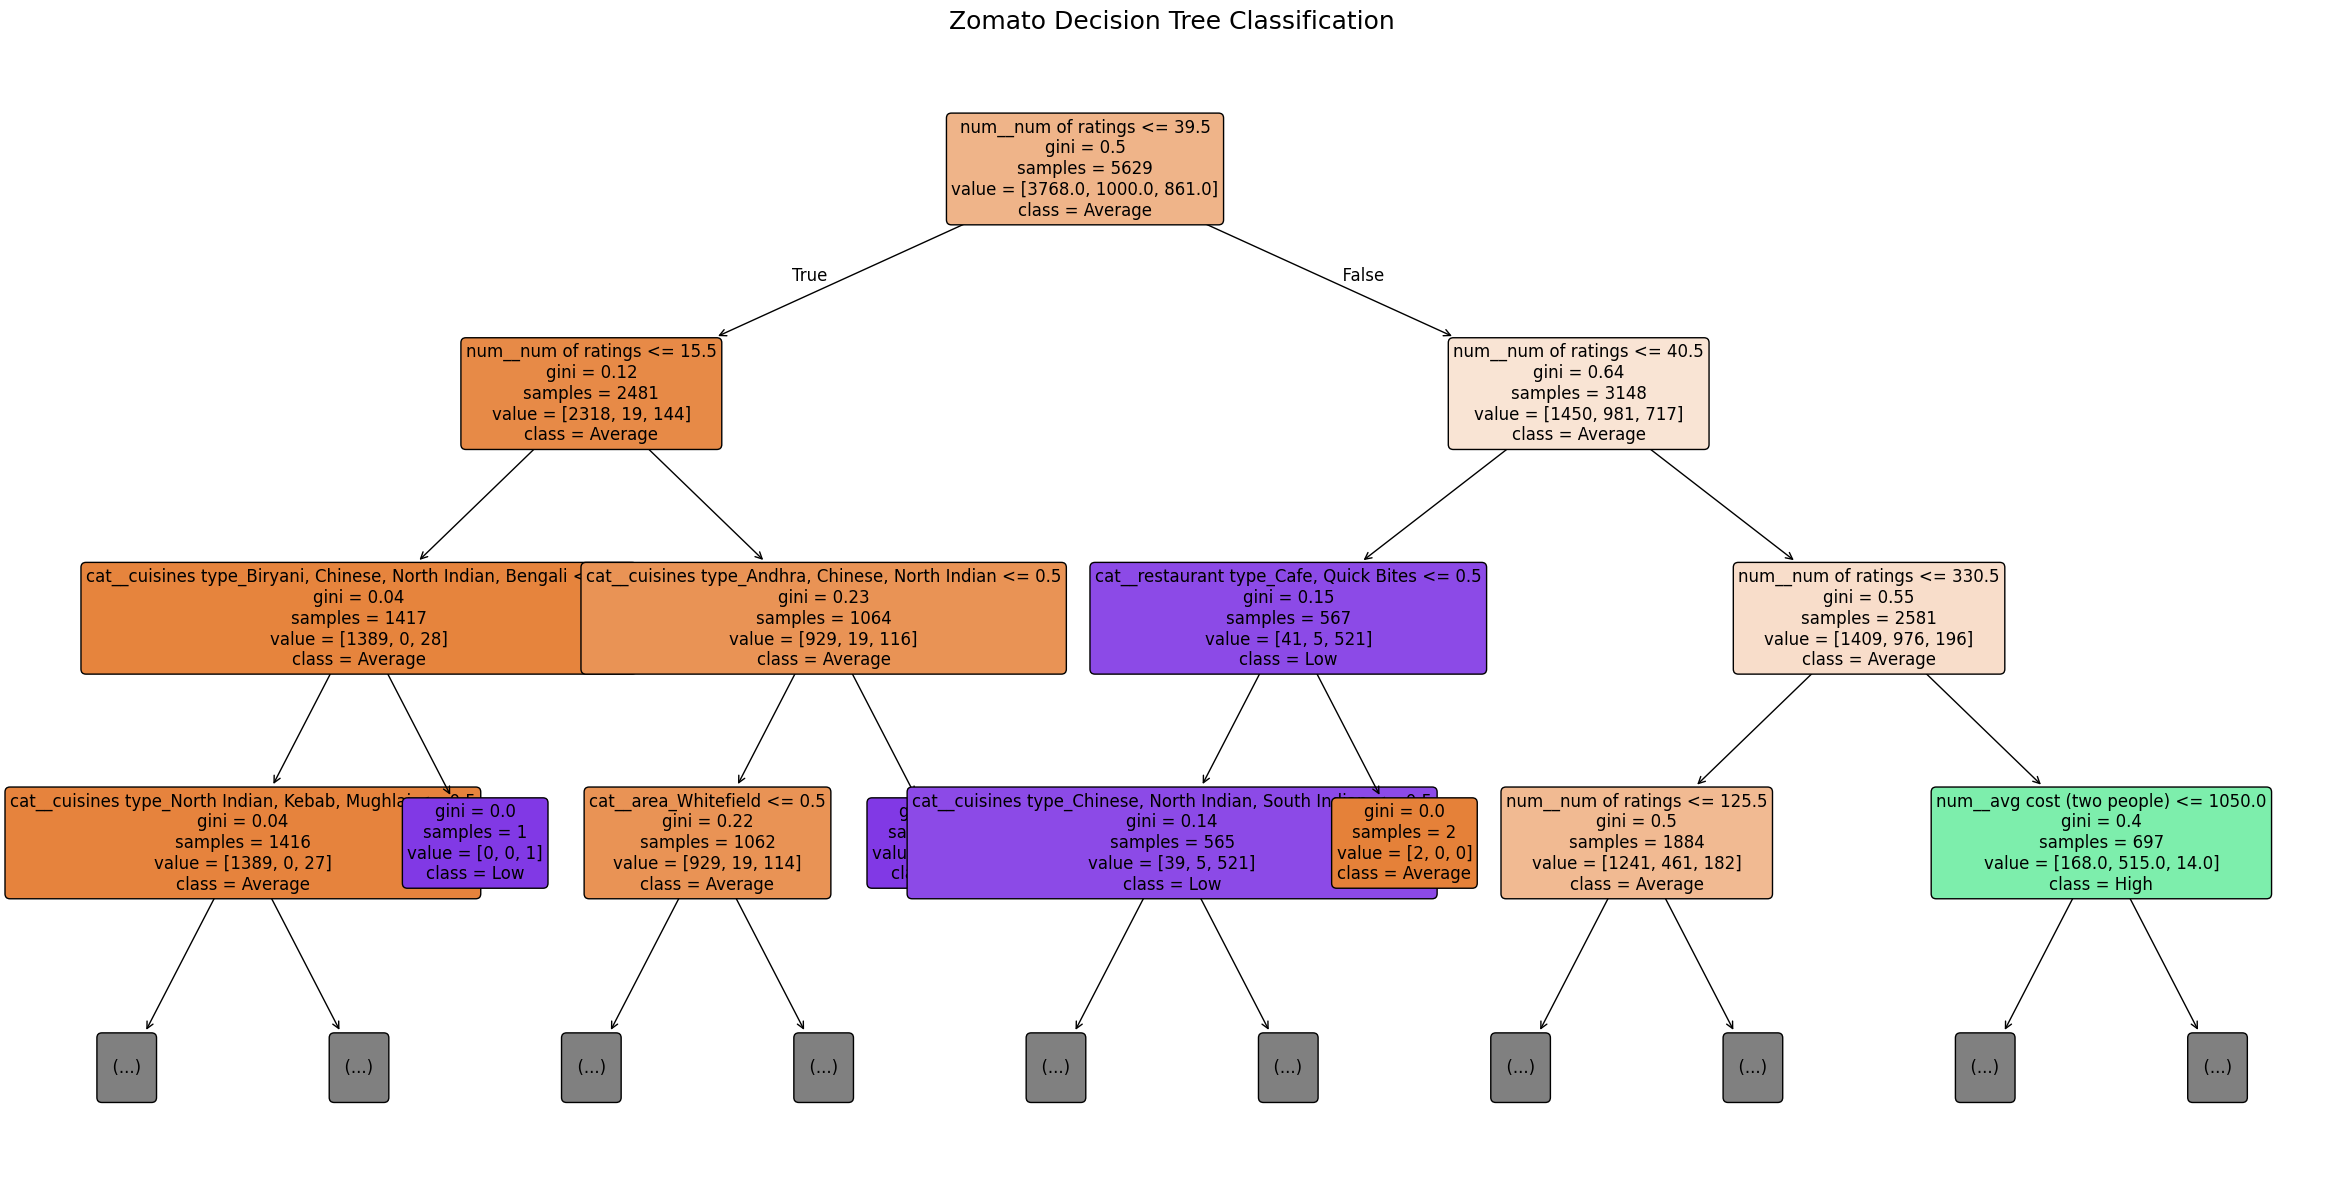

In [ ]:
from sklearn.tree import plot_tree

# Access the trained Decision Tree
trained_tree = decision_tree_model.named_steps['classifier']

# Get transformed feature names
trained_preprocessor = decision_tree_model.named_steps['preprocessor']
feature_names = trained_preprocessor.get_feature_names_out()

# Create a larger figure
plt.figure(figsize=(24, 12))

# Plot only the first 3 levels of the tree
plot_tree(
    trained_tree,
    feature_names=feature_names,
    class_names=trained_tree.classes_.astype(str),
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=12,
    proportion=False,
    precision=2
)

plt.title(
    "Zomato Decision Tree Classification",
    fontsize=18,
    pad=20
)

plt.tight_layout()
plt.show()

In [ ]:
# Custom function for building a Decision Tree

def custom_decision_tree(X_train, y_train, X_test):

    # Create the Decision Tree model
    model = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(
            criterion='entropy',
            max_depth=5,
            random_state=42
        ))
    ])

    # Train the model
    model.fit(X_train, y_train)

    # Generate predictions
    predictions = model.predict(X_test)

    return model, predictions


print("Custom Decision Tree function created successfully!")

Custom Decision Tree function created successfully!


In [ ]:
# Train the custom Decision Tree model

custom_model, custom_predictions = custom_decision_tree(
    X_train,
    y_train,
    X_test
)

print("Custom Decision Tree trained successfully!")

Custom Decision Tree trained successfully!


In [ ]:
# Calculate accuracy of custom Decision Tree

custom_accuracy = accuracy_score(
    y_test,
    custom_predictions
)

print(
    "Custom Decision Tree Accuracy:",
    round(custom_accuracy * 100, 2),
    "%"
)

Custom Decision Tree Accuracy: 82.95 %


In [ ]:
# Classification report for custom Decision Tree

print("Custom Decision Tree Classification Report:")
print(
    classification_report(
        y_test,
        custom_predictions
    )
)

Custom Decision Tree Classification Report:
              precision    recall  f1-score   support

     Average       0.83      0.95      0.89       943
        High       0.76      0.56      0.65       250
         Low       0.93      0.60      0.73       215

    accuracy                           0.83      1408
   macro avg       0.84      0.70      0.75      1408
weighted avg       0.83      0.83      0.82      1408



Custom Decision Tree Confusion Matrix:
[[899  37   7]
 [107 141   2]
 [ 80   7 128]]


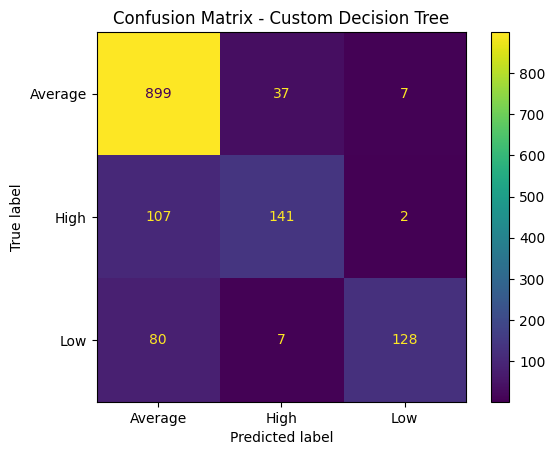

In [ ]:
# Confusion Matrix for Custom Decision Tree

custom_cm = confusion_matrix(
    y_test,
    custom_predictions,
    labels=custom_model.classes_
)

print("Custom Decision Tree Confusion Matrix:")
print(custom_cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=custom_cm,
    display_labels=custom_model.classes_
)

disp.plot()
plt.title("Confusion Matrix - Custom Decision Tree")
plt.show()

In [ ]:
# Compare the two Decision Tree models

comparison = pd.DataFrame({
    'Model': [
        'Inbuilt Decision Tree (Gini)',
        'Custom Decision Tree (Entropy)'
    ],
    'Accuracy (%)': [
        round(accuracy * 100, 2),
        round(custom_accuracy * 100, 2)
    ]
})

comparison

,Model,Accuracy (%)
0,Inbuilt Decision Tree (Gini),82.60
1,Custom Decision Tree (Entropy),82.95


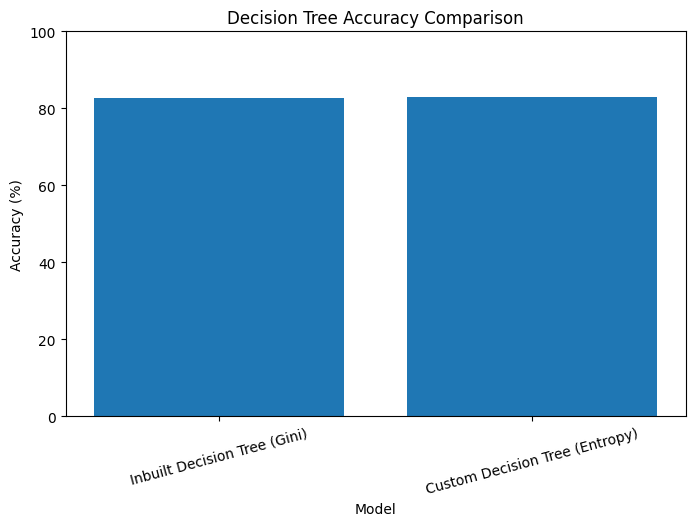

In [ ]:
# Plot accuracy comparison

plt.figure(figsize=(8, 5))

plt.bar(
    comparison['Model'],
    comparison['Accuracy (%)']
)

plt.ylabel('Accuracy (%)')
plt.xlabel('Model')
plt.title('Decision Tree Accuracy Comparison')
plt.xticks(rotation=15)
plt.ylim(0, 100)

plt.show()

In [ ]:
print("========== FINAL RESULTS ==========")

print(
    "Inbuilt Decision Tree (Gini) Accuracy:",
    round(accuracy * 100, 2),
    "%"
)

print(
    "Custom Decision Tree (Entropy) Accuracy:",
    round(custom_accuracy * 100, 2),
    "%"
)

if accuracy > custom_accuracy:
    print("\nInbuilt Decision Tree performed better.")
elif custom_accuracy > accuracy:
    print("\nCustom Decision Tree performed better.")
else:
    print("\nBoth models produced the same accuracy.")

print("===================================")

========== FINAL RESULTS ==========
Inbuilt Decision Tree (Gini) Accuracy: 82.6 %
Custom Decision Tree (Entropy) Accuracy: 82.95 %

Custom Decision Tree performed better.
